# Electricity Demand Forecast with Prior Calibration in PyMC

In [Electricity Demand Forecast: Dynamic Time-Series Model with Prior Calibration](https://juanitorduz.github.io/electricity_forecast_with_priors/) we forecast the hourly electricity demand in Victoria, Australia, with a NumPyro model. A Gaussian process describes how the effect of the temperature on the demand changes with the temperature.

We assumed that domain knowledge tells us that this effect is stable at around $0.13$ above $32$°C. We added this information to the model as an extra likelihood term on the latent effect, an idea that we took from the Pyro example [Forecasting with Dynamic Linear Model (DLM)](https://pyro.ai/examples/forecasting_dlm.html).

In this notebook we port the model to PyMC and fit it with NUTS instead of stochastic variational inference. We do not repeat the data exploration and the motivation of the model components. For these, see the NumPyro notebook and the baseline model in [Electricity Demand Forecast: Dynamic Time-Series Model](https://juanitorduz.github.io/electricity_forecast/).

Most of the port is a direct translation. Two parts need care:

- **Calibration likelihood.** PyMC does not accept a model variable as observed data, so we cannot write the calibration term as in NumPyro.
- **Calibration inputs.** In NumPyro the calibration term selects rows of the time series. We evaluate the Gaussian process at a separate array of calibration temperatures instead, so the calibration does not depend on the row positions.

The notebook has the following sections:

1. **Prepare Notebook.** We load the libraries and set the plotting style.
2. **Load Data.** We read the hourly demand and temperature and split them into training and test data.
3. **Model Specification.** We write the model in PyMC, with the calibration term on its own inputs.
4. **Model Fitting.** We sample with NUTS and check the diagnostics.
5. **Posterior Predictive Checks.** We look at the in-sample fit and the two-week forecast.
6. **Temperature Effect.** We look at the calibrated effect of the temperature on the demand.
7. **Conclusion.** We summarize the findings, the limitations and our recommendations.
8. **Next Steps.** We list two extensions of the model.

We assume that the reader knows the Hilbert space approximation of Gaussian processes (HSGP). For an introduction, see [A Conceptual and Practical Introduction to Hilbert Space GPs Approximation Methods](https://juanitorduz.github.io/hsgp_intro/).

## Prepare Notebook

In [1]:
import logging
from typing import NamedTuple

import arviz as az
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pymc as pm
import pymc.dims as pmd
import xarray as xr
from pymc_forecast import crps_empirical

seed: int = 42
rng: np.random.Generator = np.random.default_rng(seed=seed)

HDI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = HDI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

logging.getLogger("pymc").setLevel(logging.ERROR)
logging.getLogger("pytensor").setLevel(logging.ERROR)

## Load Data

We read the same data as in the NumPyro notebooks: the hourly demand (GW) and temperature (°C) in Victoria, Australia, from 2014-01-01 to 2014-02-25. The data comes from the TensorFlow Probability case study [Structural Time Series Modeling Case Studies: Atmospheric CO2 and Electricity Demand](https://www.tensorflow.org/probability/examples/Structural_Time_Series_Modeling_Case_Studies_Atmospheric_CO2_and_Electricity_Demand). We also add the hour of the day and the day of the week (Monday is $0$) as features.

In [2]:
data_df = pl.read_csv(
    "../data/electricity_demand_victoria_2014.csv", try_parse_dates=True
).with_columns(
    hour_of_day=pl.col("date").dt.hour().cast(pl.Int64),
    day_of_week=(pl.col("date").dt.weekday() - 1).cast(pl.Int64),
)

dates = data_df["date"].to_numpy()
demand = data_df["demand"].to_numpy()
temperature = data_df["temperature"].to_numpy()
hour_of_day = data_df["hour_of_day"].to_numpy()
day_of_week = data_df["day_of_week"].to_numpy()

data_df.head()

date,demand,temperature,hour_of_day,day_of_week
datetime[μs],f64,f64,i64,i64
2014-01-01 00:00:00,3.794,18.05,0,2
2014-01-01 01:00:00,3.418,17.2,1,2
2014-01-01 02:00:00,3.152,16.45,2,2
2014-01-01 03:00:00,3.026,16.65,3,2
2014-01-01 04:00:00,3.022,16.4,4,2


As in the NumPyro notebook, we hold out the last two weeks as test data.

In [3]:
n_test = 24 * 7 * 2
n_train = data_df.height - n_test
train = slice(None, n_train)
test = slice(n_train, None)

Let's plot the demand and the temperature with the training and test split.

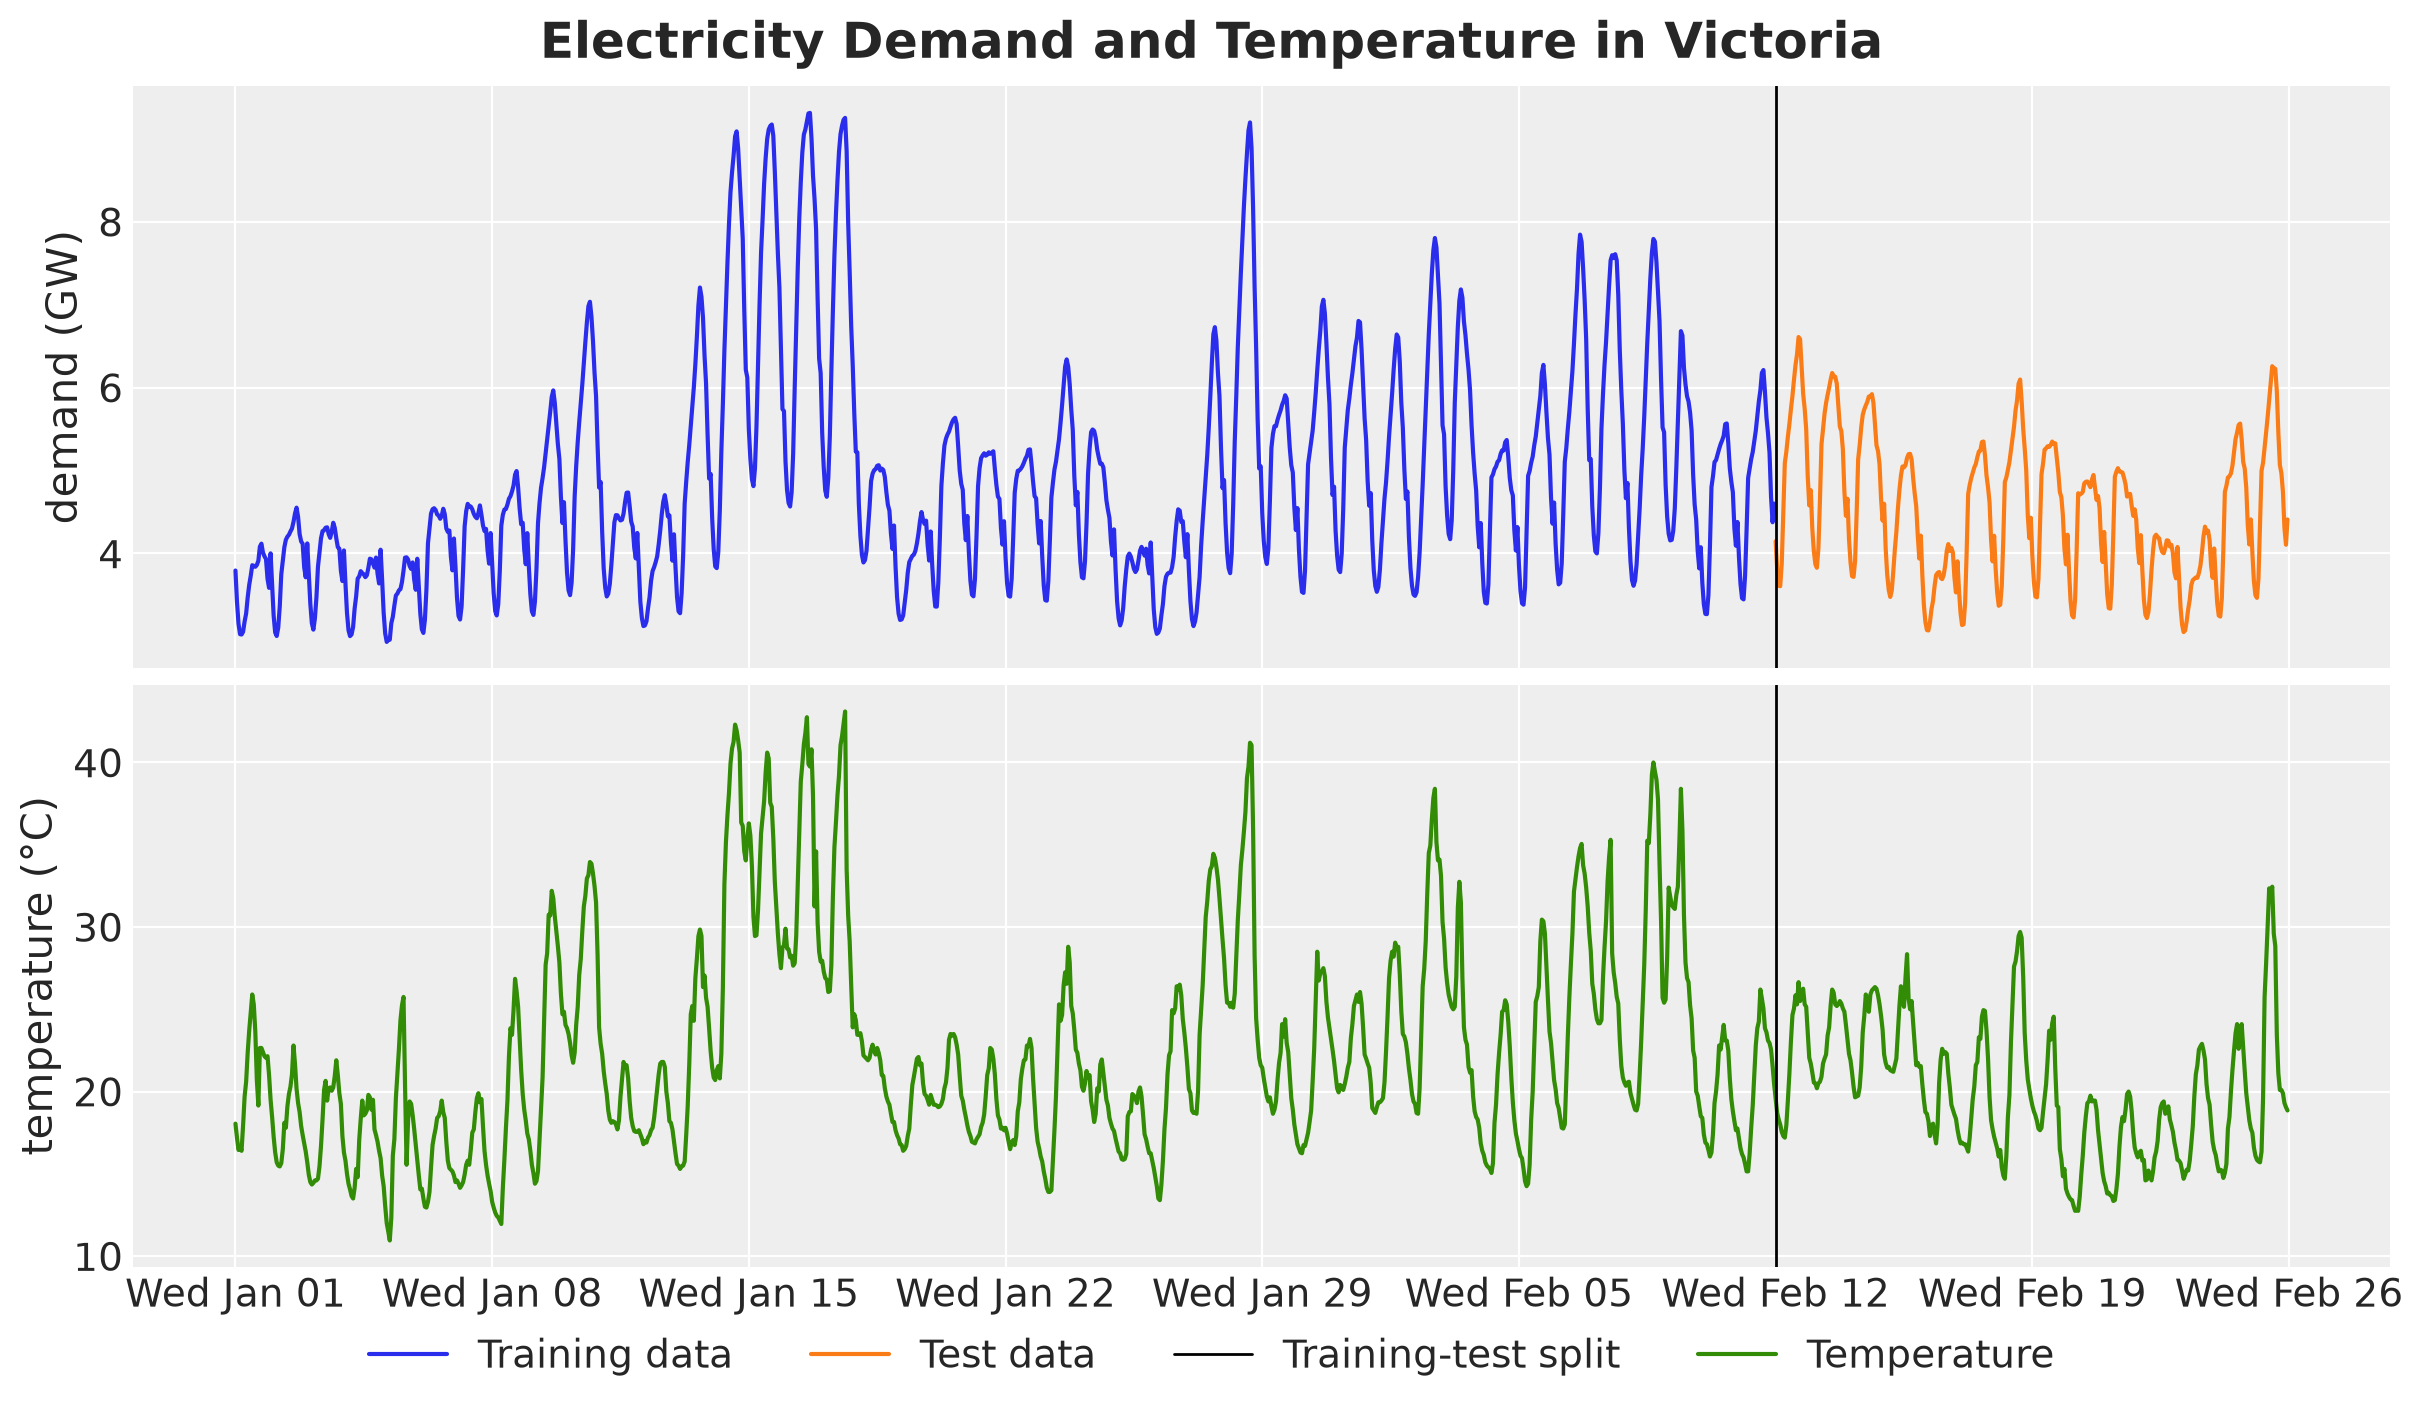

In [4]:
fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(12, 7), sharex=True, layout="constrained"
)
ax = axes[0]
ax.plot(dates[train], demand[train], color="C0", label="Training data")
ax.plot(dates[test], demand[test], color="C1", label="Test data")
ax.axvline(dates[n_train], color="black", linewidth=1, label="Training-test split")
ax.set(ylabel="demand (GW)")
ax = axes[1]
ax.plot(dates, temperature, color="C2", label="Temperature")
ax.axvline(dates[n_train], color="black", linewidth=1)
ax.set(ylabel="temperature (°C)")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.WE))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %b %d"))
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle(
    "Electricity Demand and Temperature in Victoria", fontsize=18, fontweight="bold"
);

The demand peaks on the hottest days, from 2014-01-14 to 2014-01-17 and on 2014-01-28, when the temperature goes above $40$°C. The test weeks are cooler: the temperature reaches $32$°C only on the last day.

## Model Specification

Let $y_t$ be the **demand** at hour $t$, $x_t$ the **temperature**, $h(t) \in \{0, \dots, 23\}$ the **hour of the day** and $d(t) \in \{0, \dots, 6\}$ the **day of the week**. The model is the same as in the NumPyro notebook:

$$
\begin{aligned}
y_t &\sim \text{StudentT}\left(\nu, \mu_t, \sigma \sqrt{x_t}\right), \\
\mu_t &= \beta_0 + f(x_t) \, x_t + \gamma_{h(t)} + \delta_{d(t)},
\end{aligned}
$$

where $\beta_0$ is the `intercept`, $f$ is the **temperature effect**, $\gamma$ is the `hour_of_day_effect`, $\delta$ is the `day_of_week_effect`, $\sigma$ is the `scale` and $\nu$ is the number of degrees of freedom `nu`. Note that the noise scale grows with the square root of the temperature.

The temperature effect $f$ is a Gaussian process with a Matérn $5/2$ kernel with variance $\alpha$ and length scale $\ell$. The two seasonal effects sum to zero, with scales $\sigma_h$ and $\sigma_d$. The priors are:

$$
\begin{aligned}
\beta_0 &\sim \text{Normal}(0, 2), \\
\alpha &\sim \text{InverseGamma}(6.66, 1.57), \\
\ell &\sim \text{InverseGamma}(11, 62.2), \\
\gamma &\sim \text{ZeroSumNormal}(\sigma_h), \quad \sigma_h \sim \text{HalfNormal}(0.5), \\
\delta &\sim \text{ZeroSumNormal}(\sigma_d), \quad \sigma_d \sim \text{HalfNormal}(0.5), \\
\sigma &\sim \text{HalfNormal}(0.5), \\
\nu &\sim \text{Gamma}(8, 3).
\end{aligned}
$$

### Hilbert Space Approximation

We approximate $f$ with $m = 25$ basis functions on the interval $[-L, L]$ with $L = 55$, following [Riutort-Mayol et al. (2023)](https://doi.org/10.1007/s11222-022-10167-2):

$$
f(x) \approx \sum_{j=1}^{m} \phi_j(x - c) \sqrt{S\left(\sqrt{\lambda_j}\right)} \, z_j, \qquad z_j \sim \text{Normal}(0, 1),
$$

where $\phi_j$ and $\lambda_j$ are the eigenfunctions and eigenvalues of the Laplacian on $[-L, L]$, $S$ is the spectral density of the kernel and $c$ is a **centering constant**. We build the basis with `pm.gp.HSGP.prior_linearized`, which returns $\phi_j(x - c)$ and $\sqrt{S(\sqrt{\lambda_j})}$, and we add the coefficients $z_j$ (`hsgp_coefs`) ourselves.

Here are two important remarks about the translation from NumPyro:

- **Kernel variance.** NumPyro's `hsgp_matern` multiplies the spectral density by `alpha`, so `alpha` is the variance of the kernel. In PyMC we therefore write `alpha * pm.gp.cov.Matern52(...)` without squaring `alpha`.
- **Centering.** NumPyro does not center the inputs, so $c = 0$. `pm.gp.HSGP` sets $c$ to the midpoint of the training temperatures and fixes it when we build the model. Both models approximate the same Gaussian process, but their basis functions differ, so we cannot compare the coefficients $z_j$ of the two models one to one.

### Calibration Likelihood

Let $\tilde{x}_1, \dots, \tilde{x}_K$ be the **calibration temperatures**, the training temperatures above $32$°C. The domain knowledge enters the model as the extra likelihood term

$$
\prod_{k=1}^{K} \text{Normal}\left(f(\tilde{x}_k) \mid 0.13, 0.01\right).
$$

In NumPyro we wrote this term as `numpyro.sample(..., obs=beta_temperature[idx])`. PyMC does not accept a model variable as observed data and raises a `TypeError`. Observe that the Normal density is symmetric in its argument and its location:

$$
\text{Normal}\left(f(\tilde{x}_k) \mid 0.13, 0.01\right) = \text{Normal}\left(0.13 \mid f(\tilde{x}_k), 0.01\right).
$$

Hence, we can observe the constant $0.13$ with location $f(\tilde{x}_k)$. A `pm.Potential` with the log density of the left side gives the same model. For a calibration distribution without this symmetry, such as a Gamma, we would need the potential.

### Calibration Inputs

In NumPyro we evaluated the calibration term on the rows of the time series with a temperature above $32$°C. These row indices are tied to the training window. If we refit the model on another window with `pm.set_data`, the same indices would point at other hours with other temperatures.

The calibration is a statement about the function $f$ at high temperatures. Hence, we store the calibration temperatures in their own data container and evaluate the same HSGP on them with a second call to `prior_linearized`. The second call reuses the centering constant $c$ and the boundary $L$ of the first call, so both calls share the basis functions and the coefficients $z_j$.

Now we are ready to write the PyMC model. We use `pymc.dims` for the model and the classic API for the HSGP, which `pymc.dims` does not support.

In [5]:
class Calibration(NamedTuple):
    """Domain knowledge about the temperature effect above a temperature threshold."""

    threshold: float
    mean: float
    sigma: float


calibration = Calibration(threshold=32.0, mean=0.13, sigma=0.01)
temperature_calibration = temperature[train][temperature[train] > calibration.threshold]

M = 25  # number of basis functions
L = 55.0  # boundary of the approximation interval

coords = {
    "time": dates[train],
    "hour": np.arange(24),
    "day_of_week": np.arange(7),
    "basis": np.arange(M),
    "calibration": np.arange(temperature_calibration.size),
}

with pm.Model(coords=coords) as model:
    # --- Data ---
    temperature_data = pmd.Data("temperature", temperature[train], dims="time")
    hour_idx = pmd.Data("hour_idx", hour_of_day[train], dims="time")
    day_of_week_idx = pmd.Data("day_of_week_idx", day_of_week[train], dims="time")
    demand_data = pmd.Data("demand", demand[train], dims="time")
    calibration_data = pmd.Data(
        "temperature_calibration", temperature_calibration, dims="calibration"
    )

    # --- Priors ---
    intercept = pmd.Normal("intercept", mu=0, sigma=2)
    alpha = pmd.InverseGamma("alpha", alpha=6.66, beta=1.57)
    length_scale = pmd.InverseGamma("length_scale", alpha=11, beta=62.2)
    scale = pmd.HalfNormal("scale", sigma=0.5)
    nu = pmd.Gamma("nu", alpha=8, beta=3)
    scale_hour_of_day = pmd.HalfNormal("scale_hour_of_day", sigma=0.5)
    scale_day_of_week = pmd.HalfNormal("scale_day_of_week", sigma=0.5)

    # --- Temperature effect (HSGP) ---
    cov_func = alpha.values * pm.gp.cov.Matern52(input_dim=1, ls=length_scale.values)
    gp = pm.gp.HSGP(m=[M], L=[L], cov_func=cov_func)
    # the first call fixes the centering constant at the training temperatures
    phi, sqrt_psd = gp.prior_linearized(X=temperature_data.values[:, None])
    hsgp_coefs = pmd.Normal("hsgp_coefs", mu=0, sigma=1, dims="basis")
    weights = hsgp_coefs.values * sqrt_psd
    beta_temperature = pmd.Deterministic(
        "beta_temperature", pmd.as_xtensor(phi @ weights, dims=("time",))
    )
    # the second call reuses the centering constant and the boundary
    phi_calibration, _ = gp.prior_linearized(X=calibration_data.values[:, None])
    beta_temperature_calibration = pmd.Deterministic(
        "beta_temperature_calibration",
        pmd.as_xtensor(phi_calibration @ weights, dims=("calibration",)),
    )

    # --- Seasonal effects ---
    hour_of_day_effect = pmd.ZeroSumNormal(
        "hour_of_day_effect", sigma=scale_hour_of_day, core_dims="hour", dims="hour"
    )
    day_of_week_effect = pmd.ZeroSumNormal(
        "day_of_week_effect",
        sigma=scale_day_of_week,
        core_dims="day_of_week",
        dims="day_of_week",
    )

    # --- Calibration likelihood ---
    pmd.Normal(
        "temperature_prior",
        mu=beta_temperature_calibration,
        sigma=calibration.sigma,
        observed=pmd.as_xtensor(
            np.full(temperature_calibration.size, calibration.mean),
            dims=("calibration",),
        ),
        dims="calibration",
    )

    # --- Likelihood ---
    mu = (
        intercept
        + beta_temperature * temperature_data
        + hour_of_day_effect.isel(hour=hour_idx)
        + day_of_week_effect.isel(day_of_week=day_of_week_idx)
    )
    pmd.StudentT(
        "obs",
        nu=nu,
        mu=mu,
        sigma=scale * pmd.math.sqrt(temperature_data),
        observed=demand_data,
        dims="time",
    )

Let's render the model graph.

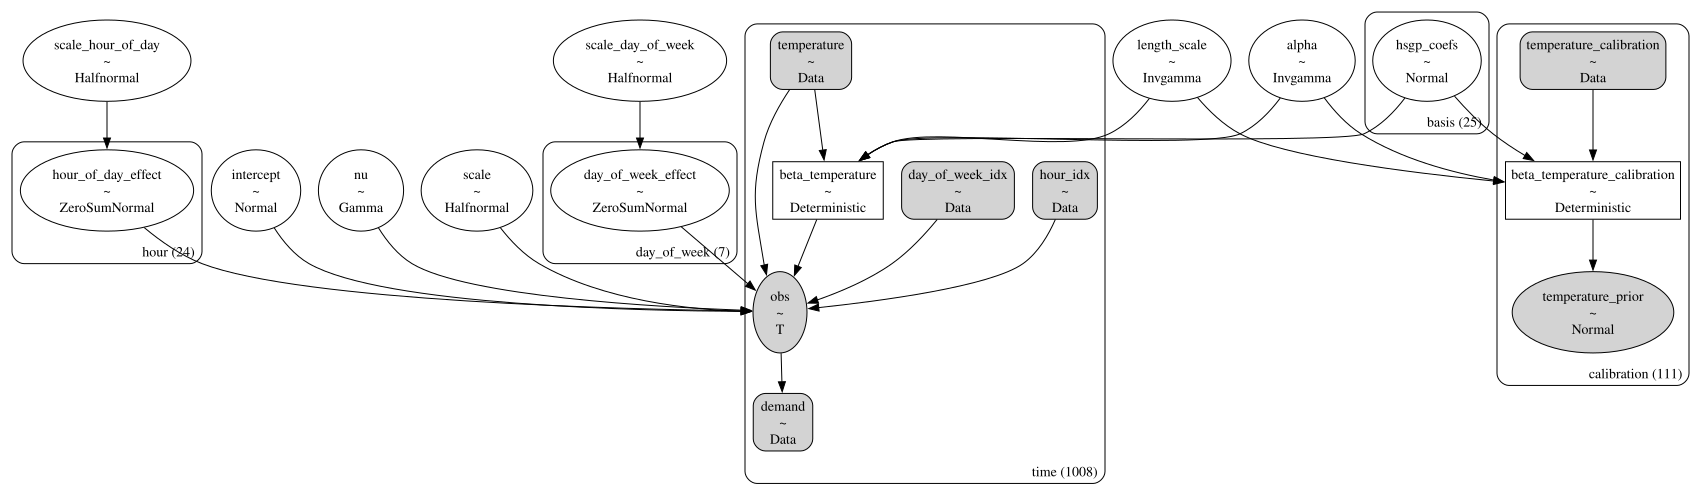

In [6]:
pm.model_to_graphviz(model)

There are $K = 111$ calibration temperatures. Before fitting, let's check that the two calls to `prior_linearized` share the basis. We draw from the prior and compare the effect at the calibration temperatures with the effect on the rows of the training data with a temperature above $32$°C.

In [7]:
prior_draws = pm.sample_prior_predictive(
    draws=500,
    model=model,
    var_names=["beta_temperature", "beta_temperature_calibration"],
    random_seed=rng,
)["prior"]

calibration_rows = np.flatnonzero(temperature[train] > calibration.threshold)
np.testing.assert_allclose(
    prior_draws["beta_temperature"].isel(time=calibration_rows).values,
    prior_draws["beta_temperature_calibration"].values,
)

The two arrays agree, so the calibration on its own inputs gives the same likelihood term as the row selection of the NumPyro model.

## Model Fitting

We fit the model with NUTS through `nutpie`. We set `target_accept=0.95` because with $0.9$ we observed a few divergent transitions.

In [8]:
with model:
    idata = pm.sample(
        draws=1_000,
        tune=1_000,
        chains=4,
        nuts_sampler="nutpie",
        target_accept=0.95,
        progressbar=False,
        random_seed=rng,
    )

Let's look at the posterior summary of the global parameters.

In [9]:
global_params = [
    "intercept",
    "alpha",
    "length_scale",
    "scale",
    "nu",
    "scale_hour_of_day",
    "scale_day_of_week",
]
az.summary(idata, var_names=global_params)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,2.518,0.068,2.4,2.6,3804,2736,1.00,0.0011,0.001
alpha,0.186,0.067,0.083,0.31,1029,1405,1.00,0.0021,0.0024
length_scale,35.6,9.8,18,53,523,846,1.00,0.42,0.23
scale,0.0881,0.00324,0.082,0.094,4820,3184,1.00,4.7e-05,4.7e-05
nu,5.64,0.86,4.2,7.3,5098,2813,1.00,0.012,0.014
scale_hour_of_day,0.42,0.065,0.31,0.54,4563,2865,1.00,0.001,0.0012
scale_day_of_week,0.311,0.107,0.16,0.5,5092,2608,1.00,0.0018,0.0029


Next, let's look at the traces. The title shows the number of divergent transitions and the largest $\hat{R}$ over all the free parameters.

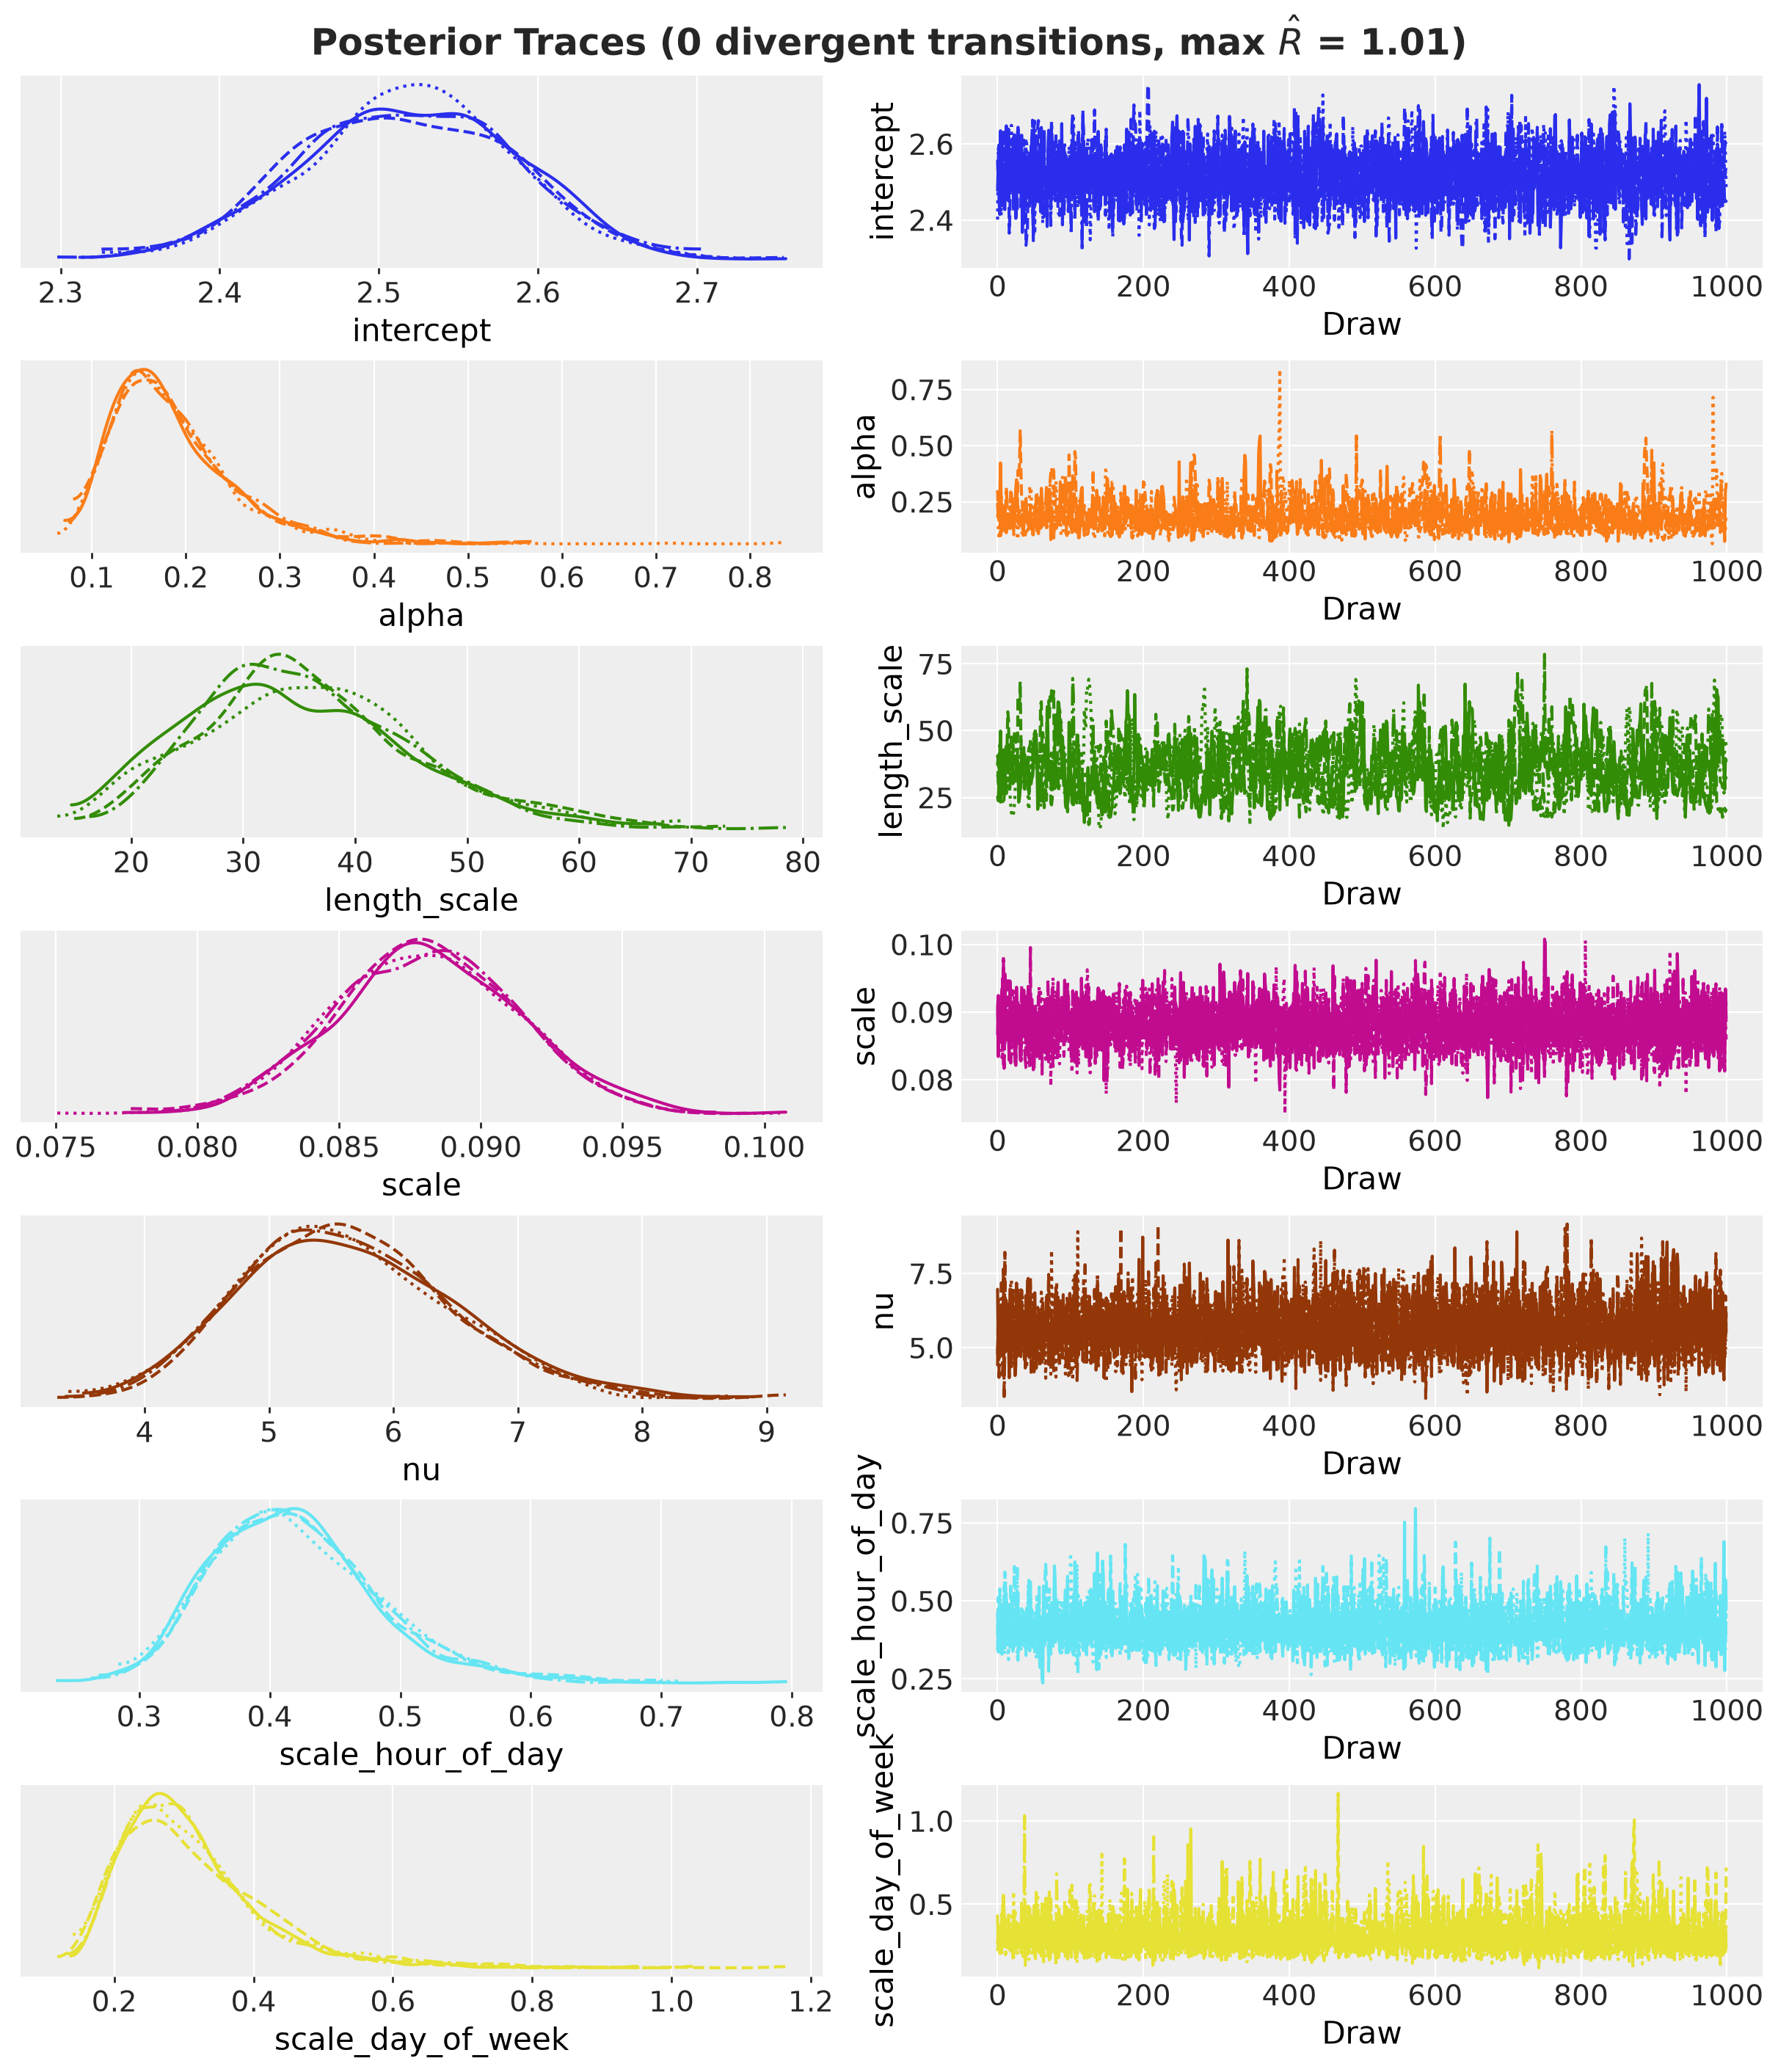

In [10]:
num_divergences = int(idata["sample_stats"]["diverging"].sum())
max_r_hat = float(
    az.summary(idata, var_names=[rv.name for rv in model.free_RVs])["r_hat"].max()
)

pc = az.plot_trace_dist(
    idata, var_names=global_params, figure_kwargs={"figsize": (12, 14)}
)
pc.viz["figure"].item().suptitle(
    f"Posterior Traces ({num_divergences} divergent transitions, "
    rf"max $\hat{{R}}$ = {max_r_hat:.2f})",
    fontsize=18,
    fontweight="bold",
);

There are no divergent transitions and $\hat{R} \leq 1.01$ for all the free parameters, which is good! Among the global parameters, the `length_scale` has the smallest bulk effective sample size ($523$), which is enough for our purposes.

## Posterior Predictive Checks

Now we sample the posterior predictive distribution on the training data. Then we replace the data containers with the full series and sample the predictions for the two test weeks. The test demand does not enter the predictions: we set the `demand` container to zeros, as it only fixes the length of the likelihood.

In [11]:
with model:
    posterior_predictive = pm.sample_posterior_predictive(
        idata, var_names=["obs"], progressbar=False, random_seed=rng
    )
    pm.set_data(
        {
            "temperature": temperature,
            "hour_idx": hour_of_day,
            "day_of_week_idx": day_of_week,
            "demand": np.zeros_like(demand),
        },
        coords={"time": dates},
    )
    predictions = pm.sample_posterior_predictive(
        idata, var_names=["obs"], predictions=True, progressbar=False, random_seed=rng
    )

As in the NumPyro notebook, we evaluate the forecast with the continuous ranked probability score (CRPS), here with `crps_empirical` from `pymc_forecast`. Let's plot the posterior predictive distribution of the whole series, with the training and test CRPS in the title.

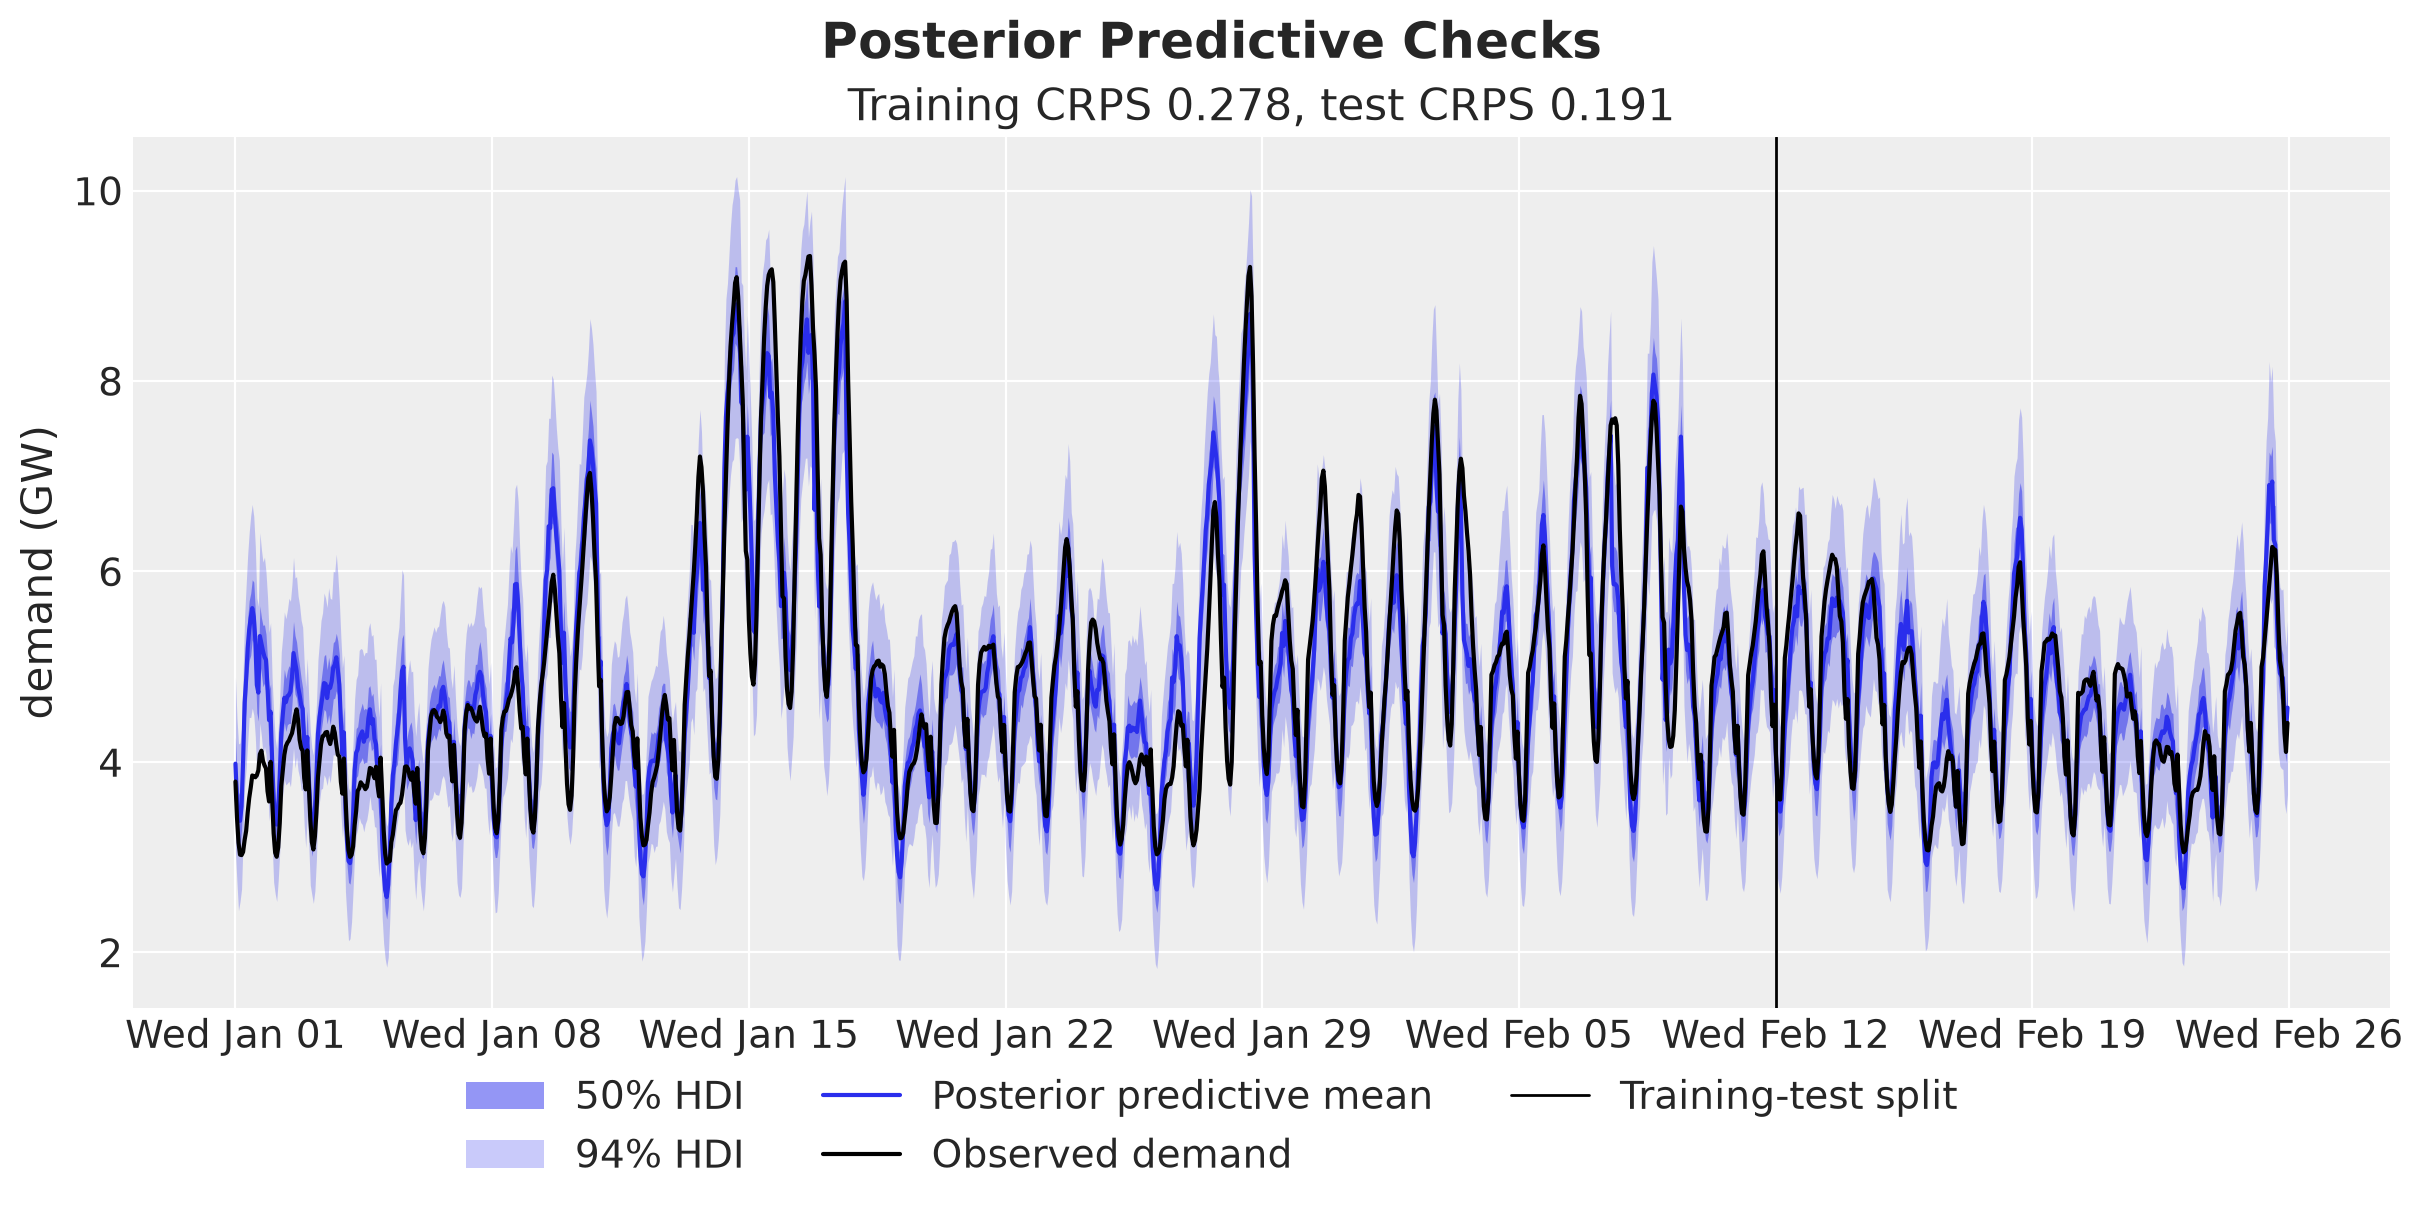

In [12]:
def lighten_bands(pc: az.PlotCollection, x: str) -> None:
    """Set the alpha of the 50% and 94% credible bands of a `plot_lm` collection."""
    bands = pc.viz["ci_band"][x]

    for prob, alpha in [(0.5, 0.5), (HDI_PROB, 0.25)]:
        for band in bands.sel(prob=prob).values.flat:
            band.set_alpha(alpha)


def lm_tree(
    name: str,
    samples: np.ndarray,
    observed: np.ndarray,
    x_name: str,
    x_values: np.ndarray,
) -> xr.DataTree:
    """ArviZ container for `plot_lm`: (chain, draw, point) samples, observed and x."""
    return az.from_dict(
        {
            "posterior_predictive": {name: samples},
            "observed_data": {name: observed},
            "constant_data": {x_name: x_values},
        },
        dims={name: ["point"], x_name: ["point"]},
    )


obs_train = posterior_predictive["posterior_predictive"]["obs"]
obs_test = predictions["predictions"]["obs"].isel(time=test)
crps_train = float(crps_empirical(obs_train, demand[train]).mean())
crps_test = float(crps_empirical(obs_test, demand[test]).mean())

obs_tree = lm_tree(
    name="obs",
    samples=np.concatenate([obs_train.values, obs_test.values], axis=-1),
    observed=demand,
    x_name="date",
    x_values=mdates.date2num(dates),
)

pc = az.plot_lm(
    obs_tree,
    x="date",
    y="obs",
    smooth=False,
    ci_prob=(0.5, HDI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C0"},
        "pe_line": {"color": "C0", "alpha": 1.0},
        "observed_scatter": False,
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "date")
pc.viz["ci_band"]["date"].sel(prob=HDI_PROB).item().set_label(f"{HDI_PROB:.0%} HDI")
pc.viz["ci_band"]["date"].sel(prob=0.5).item().set_label("50% HDI")
pc.viz["pe_line"]["date"].item().set_label("Posterior predictive mean")
ax = pc.viz["plot"]["date"].item()
ax.plot(dates, demand, color="black", label="Observed demand")
ax.axvline(dates[n_train], color="black", linewidth=1, label="Training-test split")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.WE))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %b %d"))
ax.set(
    xlabel="",
    ylabel="demand (GW)",
    title=f"Training CRPS {crps_train:.3f}, test CRPS {crps_test:.3f}",
)
fig = pc.viz["figure"].item()
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Posterior Predictive Checks", fontsize=18, fontweight="bold");

The posterior predictive distribution follows the daily cycle and the peaks of the hot days, and the forecast follows the observed demand of the two test weeks. The training and test CRPS are $0.278$ and $0.191$, very close to the $0.280$ and $0.191$ of the SVI fit in the NumPyro notebook.

## Temperature Effect

Finally, let's plot the posterior of the temperature effect $f$ against the temperature. We add the calibration mean $0.13$ and a band of one standard deviation above $32$°C.

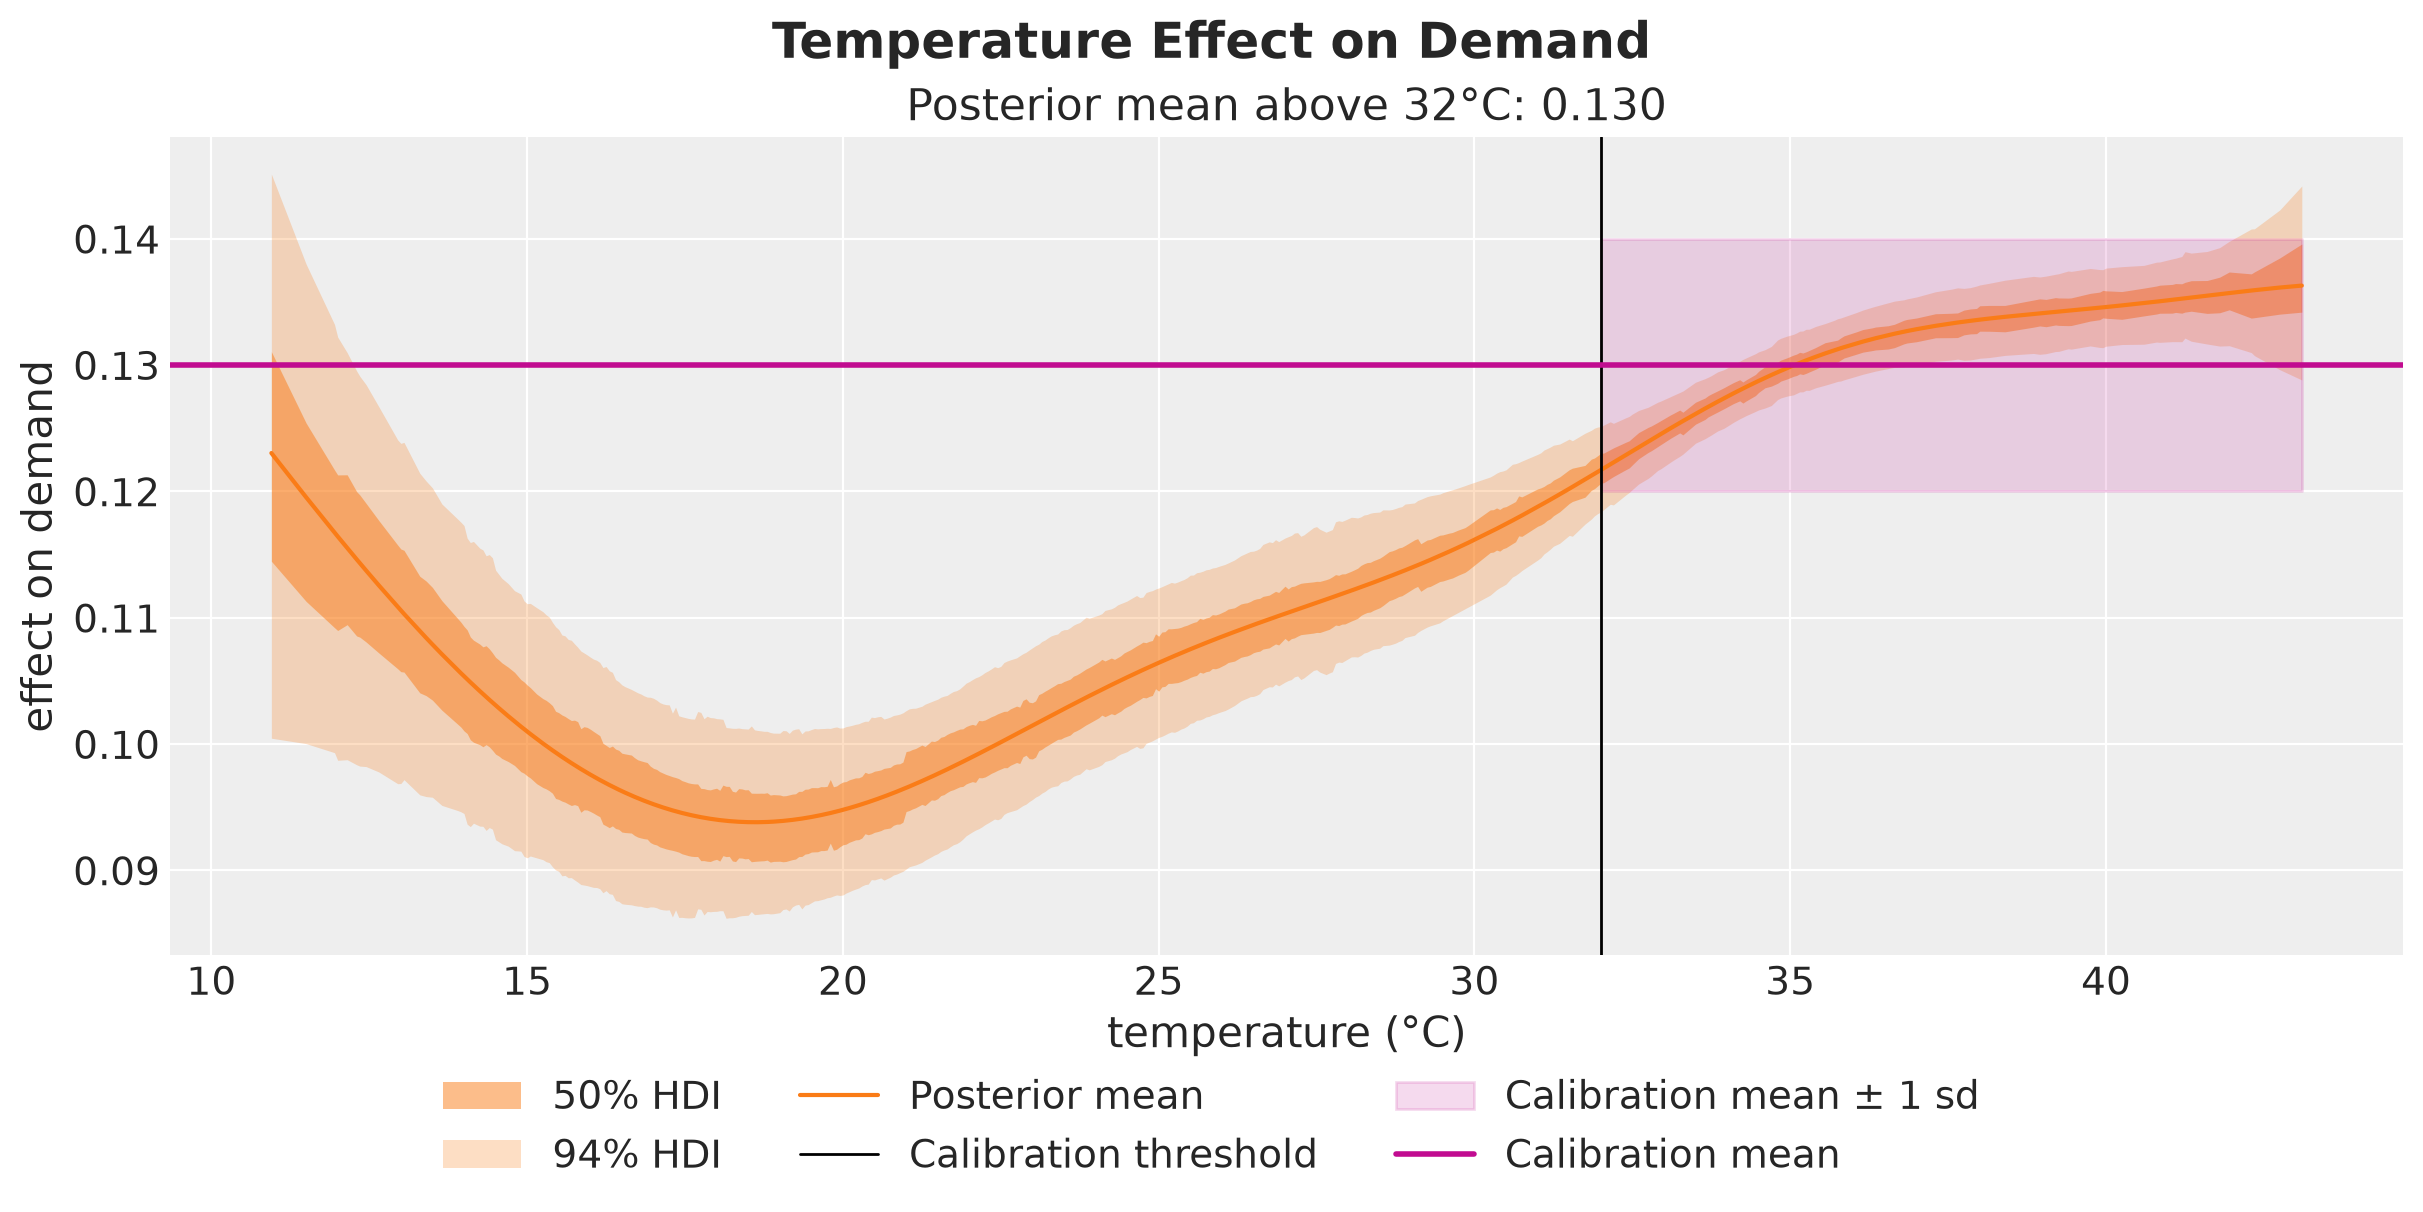

In [13]:
order = np.argsort(temperature[train])
effect = idata["posterior"]["beta_temperature"].values[..., order]
effect_above_threshold = float(
    idata["posterior"]["beta_temperature_calibration"].mean()
)

# the effect has no observed values: `plot_lm` needs the group, and we hide it
effect_tree = lm_tree(
    name="effect",
    samples=effect,
    observed=effect.mean(axis=(0, 1)),
    x_name="temperature",
    x_values=temperature[train][order],
)

pc = az.plot_lm(
    effect_tree,
    x="temperature",
    y="effect",
    smooth=False,
    ci_prob=(0.5, HDI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C1"},
        "pe_line": {"color": "C1", "alpha": 1.0},
        "observed_scatter": False,
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "temperature")
pc.viz["ci_band"]["temperature"].sel(prob=HDI_PROB).item().set_label(
    f"{HDI_PROB:.0%} HDI"
)
pc.viz["ci_band"]["temperature"].sel(prob=0.5).item().set_label("50% HDI")
pc.viz["pe_line"]["temperature"].item().set_label("Posterior mean")
ax = pc.viz["plot"]["temperature"].item()
ax.axvline(
    calibration.threshold, color="black", linewidth=1, label="Calibration threshold"
)
ax.fill_between(
    [calibration.threshold, temperature.max()],
    calibration.mean - calibration.sigma,
    calibration.mean + calibration.sigma,
    color="C3",
    alpha=0.15,
    label="Calibration mean ± 1 sd",
)
ax.axhline(calibration.mean, color="C3", linewidth=2, label="Calibration mean")
ax.set(
    xlabel="temperature (°C)",
    ylabel="effect on demand",
    title=f"Posterior mean above {calibration.threshold:g}°C: "
    f"{effect_above_threshold:.3f}",
)
fig = pc.viz["figure"].item()
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Temperature Effect on Demand", fontsize=18, fontweight="bold");

Above $32$°C the posterior mean of the effect stays inside the calibration band, and its average over the calibration temperatures is $0.130$. Below $32$°C the curve has the same shape as in the NumPyro notebook, with a minimum close to $19$°C.

Observe that the credible bands are wider than in the SVI fit of the NumPyro notebook, in particular at low temperatures, where we have few observations. This is not surprising, as mean-field variational inference tends to underestimate the posterior variance (see [Blei, Kucukelbir and McAuliffe (2017)](https://arxiv.org/abs/1601.00670)).

## Conclusion

We ported the calibrated electricity demand model from NumPyro to PyMC and fit it with NUTS. The port needs two changes in how we write the calibration term, and the forecast matches the NumPyro notebook.

### Key Findings

- **Same forecast.** The training and test CRPS are $0.278$ and $0.191$, against $0.280$ and $0.191$ with NumPyro and SVI.
- **Calibrated effect.** Above $32$°C the posterior mean of the temperature effect is $0.130$, as the domain knowledge requires.
- **Calibration likelihood.** The Normal density is symmetric in its argument and its location, so we observe the calibration mean with the latent effect as the location. A `pm.Potential` gives the same model.
- **Calibration inputs.** A second call to `prior_linearized` on the same HSGP evaluates the effect at the calibration temperatures with the same basis, so the calibration does not depend on the rows of the time series.

### Model Limitations

- **Strength of the calibration.** Every calibration temperature adds a Normal term with standard deviation $0.01$, so the strength of the calibration grows with the number $K = 111$ of hot hours in the training data.
- **Observed temperature.** The forecast uses the observed temperature of the test weeks. In practice we only have a weather forecast, so the test CRPS is optimistic.

### Recommendations

1. **Calibrate the function.** Write calibration terms on the latent function at chosen inputs and not on rows of the data, so that we can refit the model on new data with `pm.set_data`.
2. **Map the HSGP conventions.** When you port HSGP models from NumPyro, use `alpha` as the kernel variance and keep in mind that `pm.gp.HSGP` centers the inputs.

## Next Steps

1. **Calibration grid.** Calibrate on a fixed grid of temperatures above $32$°C, so that the strength of the calibration does not depend on the number of hot hours in the training window.
2. **Weather forecast scenarios.** Replace the observed temperature of the test weeks with weather forecast scenarios to get a realistic evaluation of the forecast.

## References

- Blei, D. M., Kucukelbir, A. and McAuliffe, J. D. (2017). [Variational Inference: A Review for Statisticians](https://arxiv.org/abs/1601.00670). *Journal of the American Statistical Association*, 112(518), 859-877.
- Orduz, J. (2024). [Electricity Demand Forecast: Dynamic Time-Series Model](https://juanitorduz.github.io/electricity_forecast/).
- Orduz, J. (2024). [Electricity Demand Forecast: Dynamic Time-Series Model with Prior Calibration](https://juanitorduz.github.io/electricity_forecast_with_priors/).
- Pyro. [Forecasting with Dynamic Linear Model (DLM)](https://pyro.ai/examples/forecasting_dlm.html).
- Riutort-Mayol, G., Bürkner, P.-C., Andersen, M. R., Solin, A. and Vehtari, A. (2023). [Practical Hilbert space approximate Bayesian Gaussian processes for probabilistic programming](https://doi.org/10.1007/s11222-022-10167-2). *Statistics and Computing*, 33, 17.
- TensorFlow Probability. [Structural Time Series Modeling Case Studies: Atmospheric CO2 and Electricity Demand](https://www.tensorflow.org/probability/examples/Structural_Time_Series_Modeling_Case_Studies_Atmospheric_CO2_and_Electricity_Demand).